<a href="https://colab.research.google.com/github/polinaburlacheva-eng/python-data-lab1/blob/main/Google_colabLab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Работа с Google Colab

В данном блокноте проверяется версия Python, устанавливаются и проверяются
библиотеки pandas и polars, загружается срез собственного набора данных,
проводится его первичный анализ и строится график.

In [ ]:
import sys

print("Версия Python:", sys.version)

Версия Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


### Сравнение версии Python

В Google Colab используется версия Python 3.13.16.
Требуемая версия в курсе — Python 3.12.14.
Таким образом, в Colab используется более новая версия Python.

In [ ]:
!pip install pandas polars

In [ ]:
import pandas
import polars

print("pandas:", pandas.__version__)
print("polars:", polars.__version__)

pandas: 2.2.3
polars: 1.35.2


Загрузка среза набора данных

На данном этапе в сеанс Google Colab загружается отладочный срез
набора данных, подготовленный для лабораторной работы.

In [2]:
from google.colab import files

uploaded = files.upload()

Saving games.csv to games.csv


Чтение набора данных

Загруженный CSV-файл считывается с помощью библиотеки pandas в DataFrame
для дальнейшего анализа.

In [3]:
import pandas as pd

df = pd.read_csv("games.csv")

df.head()

,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,DiscountDLC count,About the game,Supported languages,...,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Developers,Publishers,Categories,Genres,Tags,Screenshots,Movies
0,Black Dragon Mage Playtest,"Aug 1, 2023",0 - 0,0,0,0.00,0,0,NaN,[],...,0,0,0,NaN,NaN,NaN,NaN,NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
1,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",0 - 20000,0,0,5.24,65,0,"Springtime, April: when the cherry trees come ...",['English'],...,0,8,0,minori,MangaGamer,"Single-player,Steam Trading Cards,Steam Cloud,...",Adventure,"Adventure,Visual Novel,Anime,Cute",https://shared.akamai.steamstatic.com/store_it...,NaN
2,Mystery Solitaire The Black Raven,"May 6, 2019",0 - 20000,0,0,4.99,0,0,"Immerse yourself in the most beloved, mystical...","['English', 'French', 'German', 'Russian']",...,0,0,0,Somer Games,8floor,"Single-player,Family Sharing",Casual,"Casual,Card Game,Solitaire,Puzzle,Hidden Objec...",https://shared.akamai.steamstatic.com/store_it...,NaN
3,버튜버 파라노이아 - Vtuber Paranoia,"Oct 31, 2024",0 - 20000,1,0,8.99,0,1,"synopsis 'Hello, I'm Hiyoro, a new YouTuber!' ...",['Korean'],...,0,0,0,유진게임즈,유진게임즈,"Single-player,Steam Achievements,Family Sharing","Casual,Indie,Simulation",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
4,Maze Quest VR,"Apr 24, 2025",0 - 20000,0,0,4.99,0,0,Its not just a Maze; its a Quest! Enter the ca...,['English'],...,0,0,0,Reality Expanded LLC,Reality Expanded LLC,"Single-player,VR Only,Steam Leaderboards,Famil...","Action,Early Access",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN


In [ ]:
print("Количество строк:", df.shape[0])
print("Количество столбцов:", df.shape[1])

Количество строк: 200000
Количество столбцов: 27


Столбцы и типы данных

Выведем названия всех столбцов набора данных и тип данных, который
используется для хранения значений в каждом столбце.

In [4]:
for column in df.columns:
    print(column, "—", df[column].dtype)

AppID — object
Name — object
Release date — object
Estimated owners — int64
Peak CCU — int64
Required age — float64
Price — int64
DiscountDLC count — int64
About the game — object
Supported languages — object
Full audio languages — object
Reviews — object
Header image — object
Website — object
Support url — object
Support email — object
Windows — bool
Mac — bool
Linux — bool
Metacritic score — int64
Metacritic url — object
User score — int64
Positive — int64
Negative — int64
Score rank — float64
Achievements — int64
Recommendations — int64
Notes — object
Average playtime forever — int64
Average playtime two weeks — int64
Median playtime forever — int64
Median playtime two weeks — int64
Developers — object
Publishers — object
Categories — object
Genres — object
Tags — object
Screenshots — object
Movies — float64


Доля пропущенных значений

Для каждого столбца вычислим долю пропущенных значений от общего количества
строк в наборе данных.

In [5]:
missing_share = df.isna().mean() * 100

print("Доля пропусков по столбцам (%):")
print(missing_share)

Доля пропусков по столбцам (%):
AppID                           0.000795
Name                            0.000000
Release date                    0.000000
Estimated owners                0.000000
Peak CCU                        0.000000
Required age                    0.000000
Price                           0.000000
DiscountDLC count               0.000000
About the game                  6.723611
Supported languages             0.000000
Full audio languages            0.000000
Reviews                        90.321402
Header image                    0.064360
Website                        59.858567
Support url                    56.064519
Support email                  17.981010
Windows                         0.000000
Mac                             0.000000
Linux                           0.000000
Metacritic score                0.000000
Metacritic url                 96.616741
User score                      0.000000
Positive                        0.000000
Negative                 

Количество записей по годам

Построим график, показывающую распределение цен компьютерных игр в Steam на основе столбца Price. Это позволяет увидеть, какие ценовые диапазоны наиболее распространены в наборе данных.

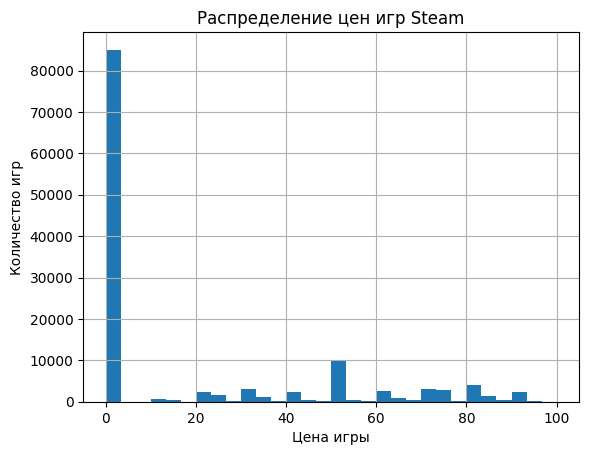

In [7]:
import matplotlib.pyplot as plt

# Строим гистограмму распределения цен игр
df["Price"].hist(bins=30)

plt.title("Распределение цен игр Steam")
plt.xlabel("Цена игры")
plt.ylabel("Количество игр")
plt.show()

Вывод

В ходе работы была проверена версия Python в Google Colab и выполнено сравнение с требуемой версией Python 3.12.14. Были установлены и проверены библиотеки pandas и polars.

В Colab был загружен отладочный срез набора данных Steam Games Dataset. С помощью pandas были определены количество строк и столбцов, названия и типы столбцов, а также доля пропущенных значений.

Для визуального анализа была построена гистограмма распределения цен компьютерных игр на основе столбца Price. График позволяет оценить, какие цены чаще встречаются в наборе данных.